In [12]:
# Cell 9: Copy the dataset from Google Drive to Colab local storage

import shutil
import os

local_dataset_root = "/content/classification_task"

if not os.path.exists(local_dataset_root):
    print("Copying dataset from Google Drive to local storage...")
    shutil.copytree(dataset_root, local_dataset_root)
    print("Dataset copied successfully!")
else:
    print("Dataset already exists in local storage.")

# Update paths to local storage
train_dir = os.path.join(local_dataset_root, "train")
test_dir = os.path.join(local_dataset_root, "test")

print("\nLocal dataset path:", local_dataset_root)
print("Train path:", train_dir)
print("Test path:", test_dir)

Copying dataset from Google Drive to local storage...
Dataset copied successfully!

Local dataset path: /content/classification_task
Train path: /content/classification_task/train
Test path: /content/classification_task/test


In [13]:
# Cell 10: Remove exact duplicates and train-test leakage

import os
import hashlib
from PIL import Image
from collections import defaultdict

# Hash each image using grayscale pixel data and dimensions
def get_image_hash(image_path):
    with Image.open(image_path) as img:
        img = img.convert("L")
        image_data = img.tobytes()
        image_size = img.size

    hash_object = hashlib.sha256()
    hash_object.update(str(image_size).encode())
    hash_object.update(image_data)

    return hash_object.hexdigest()


# Collect training and testing image paths
train_files = []
test_files = []

for class_name in os.listdir(train_dir):
    class_path = os.path.join(train_dir, class_name)

    if os.path.isdir(class_path):
        for filename in os.listdir(class_path):
            train_files.append(
                (os.path.join(class_path, filename), class_name)
            )

for class_name in os.listdir(test_dir):
    class_path = os.path.join(test_dir, class_name)

    if os.path.isdir(class_path):
        for filename in os.listdir(class_path):
            test_files.append(
                (os.path.join(class_path, filename), class_name)
            )


# Calculate hashes
train_hashes = {}
test_hashes = set()

for path, label in train_files:
    train_hashes[path] = get_image_hash(path)

for path, label in test_files:
    test_hashes.add(get_image_hash(path))


# Remove images that exist in the test set
leakage_files = {
    path for path, image_hash in train_hashes.items()
    if image_hash in test_hashes
}


# Identify internal training duplicates
hash_groups = defaultdict(list)

for path, image_hash in train_hashes.items():
    if image_hash not in test_hashes:
        hash_groups[image_hash].append(path)


# Keep one copy of each internal duplicate group
internal_duplicate_files = set()

for paths in hash_groups.values():
    if len(paths) > 1:
        internal_duplicate_files.update(paths[1:])


# Combine removal decisions
files_to_remove = leakage_files | internal_duplicate_files


# Remove selected files
for path in files_to_remove:
    os.remove(path)


# Display cleaning results
print("Exact duplicate cleaning completed!")
print("-" * 45)
print("Original training images:", len(train_files))
print("Train-test duplicate images removed:", len(leakage_files))
print("Internal training duplicates removed:", len(internal_duplicate_files))
print("Total removed:", len(files_to_remove))
print("Remaining training images:", len(train_files) - len(files_to_remove))
print("Test images:", len(test_files), "(untouched)")

Exact duplicate cleaning completed!
---------------------------------------------
Original training images: 5000
Train-test duplicate images removed: 104
Internal training duplicates removed: 32
Total removed: 136
Remaining training images: 4864
Test images: 1000 (untouched)


In [14]:
# Cell 11: Create stratified train-validation split

from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split
from collections import Counter

# Load the cleaned training dataset
clean_train_dataset = ImageFolder(train_dir)

# Load the untouched test dataset
test_dataset = ImageFolder(test_dir)

classes = clean_train_dataset.classes
class_to_idx = clean_train_dataset.class_to_idx

# Create stratified 80/20 split
train_indices, val_indices = train_test_split(
    list(range(len(clean_train_dataset))),
    test_size=0.20,
    random_state=42,
    stratify=clean_train_dataset.targets
)

# Get labels for each split
train_labels = [clean_train_dataset.targets[i] for i in train_indices]
val_labels = [clean_train_dataset.targets[i] for i in val_indices]

# Display split information
print("Dataset split completed!")
print("-" * 45)

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))
print("Test samples:", len(test_dataset))

print("\nTraining class distribution:")
for class_name, count in zip(classes, Counter(train_labels).values()):
    print(f"{class_name}: {count}")

print("\nValidation class distribution:")
for class_name, count in zip(classes, Counter(val_labels).values()):
    print(f"{class_name}: {count}")

Dataset split completed!
---------------------------------------------
Training samples: 3891
Validation samples: 973
Test samples: 1000

Training class distribution:
glioma: 846
meningioma: 1152
no_tumor: 918
pituitary: 975

Validation class distribution:
glioma: 244
meningioma: 288
no_tumor: 212
pituitary: 229


In [15]:
# Cell 12: Correct class distribution display

from collections import Counter

train_counter = Counter(train_labels)
val_counter = Counter(val_labels)

print("Training class distribution:")
for class_name in classes:
    label = class_to_idx[class_name]
    print(f"{class_name}: {train_counter[label]}")

print("\nValidation class distribution:")
for class_name in classes:
    label = class_to_idx[class_name]
    print(f"{class_name}: {val_counter[label]}")

Training class distribution:
glioma: 918
meningioma: 975
no_tumor: 846
pituitary: 1152

Validation class distribution:
glioma: 229
meningioma: 244
no_tumor: 212
pituitary: 288


In [16]:
# Cell 13: EfficientNet preprocessing and DataLoaders

from torchvision import models, datasets
from torch.utils.data import Subset, DataLoader

# Load EfficientNet-B0 pretrained weights
weights = models.EfficientNet_B0_Weights.DEFAULT

# Use official preprocessing for these weights
efficientnet_transform = weights.transforms()

# Reload datasets with EfficientNet preprocessing
full_train_dataset = datasets.ImageFolder(
    train_dir,
    transform=efficientnet_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=efficientnet_transform
)

# Create training and validation subsets
train_dataset = Subset(full_train_dataset, train_indices)
val_dataset = Subset(full_train_dataset, val_indices)

# DataLoader configuration
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Display configuration
print("EfficientNet preprocessing:")
print(efficientnet_transform)

print("\nDataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

EfficientNet preprocessing:
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)

DataLoaders created successfully!
Training batches: 122
Validation batches: 31
Testing batches: 32


In [17]:
# Cell 14: Initialize EfficientNet-B0 feature extractor

import torch
import torch.nn as nn
from torchvision import models

# Load pretrained EfficientNet-B0
efficientnet = models.efficientnet_b0(weights=weights)

# Remove the classification layer
efficientnet.classifier = nn.Identity()

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Move model to device
efficientnet = efficientnet.to(device)

# Set model to evaluation mode
efficientnet.eval()

# Freeze all model parameters
for param in efficientnet.parameters():
    param.requires_grad = False

# Display model information
print("EfficientNet-B0 initialized successfully!")
print("Device:", device)
print("Feature dimension: 1280")
print("Model mode:", "Evaluation")
print("Parameters frozen:", True)

EfficientNet-B0 initialized successfully!
Device: cuda
Feature dimension: 1280
Model mode: Evaluation
Parameters frozen: True


In [18]:
# Cell 15: Extract EfficientNet-B0 features and save them to Google Drive

import numpy as np
import os
import time
from tqdm.auto import tqdm

# Create feature storage directory
feature_dir = "/content/drive/MyDrive/BrainTumorClassification/features"
os.makedirs(feature_dir, exist_ok=True)

# Feature extraction function
def extract_features(loader, dataset_name):
    features = []
    labels = []

    start_time = time.time()

    print(f"\nExtracting {dataset_name} features...")

    with torch.inference_mode():
        for images, batch_labels in tqdm(loader, desc=dataset_name):

            images = images.to(device, non_blocking=True)

            batch_features = efficientnet(images)

            features.append(batch_features.cpu().numpy())
            labels.append(batch_labels.numpy())

    X = np.concatenate(features, axis=0)
    y = np.concatenate(labels, axis=0)

    # Save extracted features immediately
    save_path = os.path.join(feature_dir, f"efficientnet_{dataset_name}.npz")

    np.savez_compressed(
        save_path,
        X=X,
        y=y
    )

    elapsed_time = time.time() - start_time

    print(f"\n{dataset_name} extraction completed!")
    print("Feature shape:", X.shape)
    print("Label shape:", y.shape)
    print(f"Time taken: {elapsed_time / 60:.2f} minutes")
    print("Saved to:", save_path)

    return X, y


# Extract training features
X_train, y_train = extract_features(train_loader, "train")

# Extract validation features
X_val, y_val = extract_features(val_loader, "val")

# Extract testing features
X_test, y_test = extract_features(test_loader, "test")


# Display final feature shapes
print("\n" + "=" * 50)
print("ALL FEATURE EXTRACTION COMPLETED")
print("=" * 50)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nAll features saved successfully in Google Drive!")


Extracting train features...


train:   0%|          | 0/122 [00:00<?, ?it/s]


train extraction completed!
Feature shape: (3891, 1280)
Label shape: (3891,)
Time taken: 0.55 minutes
Saved to: /content/drive/MyDrive/BrainTumorClassification/features/efficientnet_train.npz

Extracting val features...


val:   0%|          | 0/31 [00:00<?, ?it/s]


val extraction completed!
Feature shape: (973, 1280)
Label shape: (973,)
Time taken: 0.13 minutes
Saved to: /content/drive/MyDrive/BrainTumorClassification/features/efficientnet_val.npz

Extracting test features...


test:   0%|          | 0/32 [00:00<?, ?it/s]


test extraction completed!
Feature shape: (1000, 1280)
Label shape: (1000,)
Time taken: 0.15 minutes
Saved to: /content/drive/MyDrive/BrainTumorClassification/features/efficientnet_test.npz

ALL FEATURE EXTRACTION COMPLETED
X_train: (3891, 1280)
y_train: (3891,)
X_val: (973, 1280)
y_val: (973,)
X_test: (1000, 1280)
y_test: (1000,)

All features saved successfully in Google Drive!


In [19]:
# Cell 16: Train SVM baseline using EfficientNet features

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

# Create SVM pipeline
svm_baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        C=1,
        kernel="rbf",
        gamma="scale"
    ))
])

# Train the model
print("Training SVM baseline...")

svm_baseline.fit(X_train, y_train)

print("SVM baseline training completed!")

Training SVM baseline...
SVM baseline training completed!


SVM Baseline Validation Results
Validation Accuracy: 95.48%

Classification Report:
              precision    recall  f1-score   support

      glioma       1.00      0.89      0.94       229
  meningioma       0.90      0.95      0.93       244
    no_tumor       0.97      0.99      0.98       212
   pituitary       0.96      0.98      0.97       288

    accuracy                           0.95       973
   macro avg       0.96      0.95      0.95       973
weighted avg       0.96      0.95      0.95       973



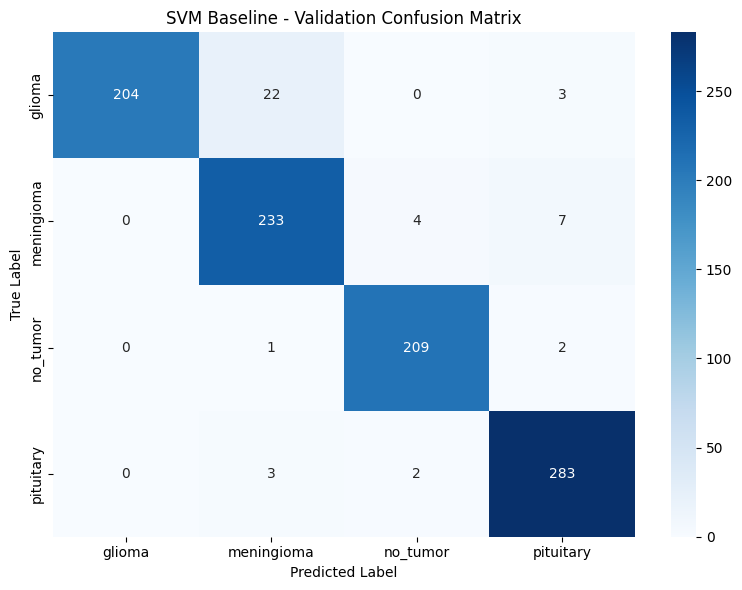

In [20]:
# Cell 17: Evaluate SVM baseline on validation data

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Predict validation labels
y_val_pred_svm = svm_baseline.predict(X_val)

# Calculate validation accuracy
svm_val_accuracy = accuracy_score(y_val, y_val_pred_svm)

print("SVM Baseline Validation Results")
print("=" * 50)
print(f"Validation Accuracy: {svm_val_accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_svm,
    target_names=classes
))

# Confusion matrix
cm_svm = confusion_matrix(y_val, y_val_pred_svm)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("SVM Baseline - Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [21]:
# Cell 18: SVM hyperparameter tuning

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

C_values = [0.1, 1, 10, 100]
gamma_values = ["scale", "auto"]

svm_results = []

best_svm_accuracy = 0
best_svm_model = None
best_svm_params = None

print("Starting SVM hyperparameter tuning...\n")

for C in C_values:
    for gamma in gamma_values:

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("svm", SVC(
                C=C,
                kernel="rbf",
                gamma=gamma
            ))
        ])

        model.fit(X_train, y_train)

        y_pred = model.predict(X_val)
        accuracy = accuracy_score(y_val, y_pred)

        svm_results.append({
            "C": C,
            "gamma": gamma,
            "validation_accuracy": accuracy
        })

        print(f"C={C:<5} | gamma={gamma:<6} | Accuracy={accuracy * 100:.2f}%")

        if accuracy > best_svm_accuracy:
            best_svm_accuracy = accuracy
            best_svm_model = model
            best_svm_params = {
                "C": C,
                "gamma": gamma
            }

print("\n" + "=" * 50)
print("BEST SVM CONFIGURATION")
print("=" * 50)

print("Best parameters:", best_svm_params)
print(f"Best validation accuracy: {best_svm_accuracy * 100:.2f}%")

Starting SVM hyperparameter tuning...

C=0.1   | gamma=scale  | Accuracy=89.00%
C=0.1   | gamma=auto   | Accuracy=89.00%
C=1     | gamma=scale  | Accuracy=95.48%
C=1     | gamma=auto   | Accuracy=95.48%
C=10    | gamma=scale  | Accuracy=96.92%
C=10    | gamma=auto   | Accuracy=96.92%
C=100   | gamma=scale  | Accuracy=96.92%
C=100   | gamma=auto   | Accuracy=96.92%

BEST SVM CONFIGURATION
Best parameters: {'C': 10, 'gamma': 'scale'}
Best validation accuracy: 96.92%


Tuned SVM Validation Results
Validation Accuracy: 96.92%

Classification Report:
              precision    recall  f1-score   support

      glioma       1.00      0.93      0.96       229
  meningioma       0.93      0.98      0.95       244
    no_tumor       0.98      0.99      0.98       212
   pituitary       0.98      0.98      0.98       288

    accuracy                           0.97       973
   macro avg       0.97      0.97      0.97       973
weighted avg       0.97      0.97      0.97       973



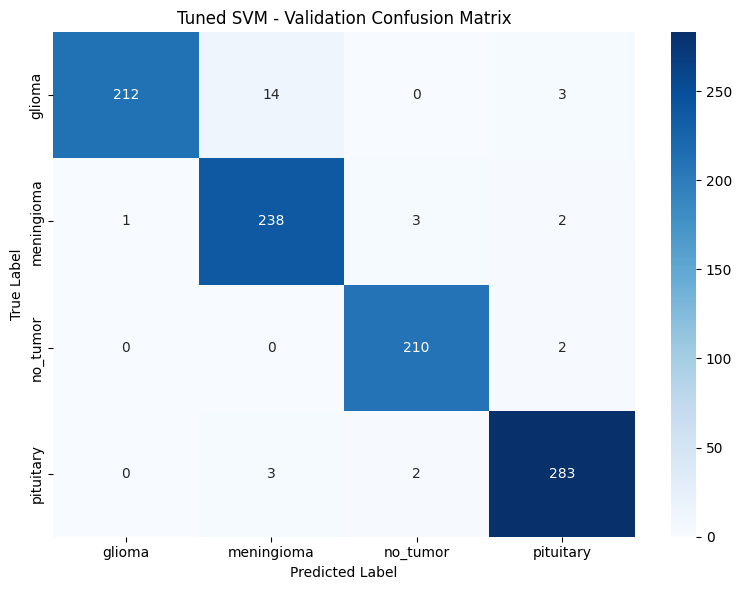

In [22]:
# Cell 19: Detailed evaluation of tuned SVM

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# Predict validation labels using the best SVM
y_val_pred_tuned_svm = best_svm_model.predict(X_val)

# Calculate accuracy
tuned_svm_accuracy = accuracy_score(y_val, y_val_pred_tuned_svm)

print("Tuned SVM Validation Results")
print("=" * 50)
print(f"Validation Accuracy: {tuned_svm_accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_tuned_svm,
    target_names=classes
))

# Confusion matrix
cm_tuned_svm = confusion_matrix(
    y_val,
    y_val_pred_tuned_svm
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_tuned_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Tuned SVM - Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [23]:
# Cell 20: Train Random Forest baseline

from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
print("Training Random Forest baseline...")

rf_baseline.fit(X_train, y_train)

print("Random Forest baseline training completed!")

Training Random Forest baseline...
Random Forest baseline training completed!


Random Forest Baseline Validation Results
Validation Accuracy: 92.81%

Classification Report:
              precision    recall  f1-score   support

      glioma       0.97      0.85      0.91       229
  meningioma       0.87      0.90      0.89       244
    no_tumor       0.97      0.95      0.96       212
   pituitary       0.92      1.00      0.96       288

    accuracy                           0.93       973
   macro avg       0.93      0.92      0.93       973
weighted avg       0.93      0.93      0.93       973



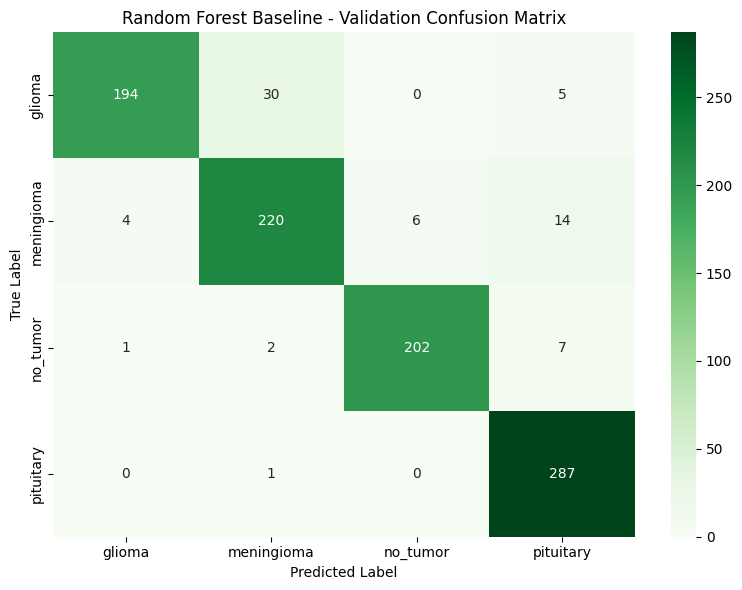

In [24]:
# Cell 21: Evaluate Random Forest baseline

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Predict validation labels
y_val_pred_rf = rf_baseline.predict(X_val)

# Calculate validation accuracy
rf_val_accuracy = accuracy_score(y_val, y_val_pred_rf)

print("Random Forest Baseline Validation Results")
print("=" * 50)
print(f"Validation Accuracy: {rf_val_accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_rf,
    target_names=classes
))

# Confusion matrix
cm_rf = confusion_matrix(y_val, y_val_pred_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Random Forest Baseline - Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [25]:
# Cell 22: Random Forest hyperparameter tuning

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

n_estimators_values = [300, 500]
max_depth_values = [20, 30, None]
min_samples_leaf_values = [1, 2]

rf_results = []

best_rf_accuracy = 0
best_rf_model = None
best_rf_params = None

print("Starting Random Forest hyperparameter tuning...\n")

for n_estimators in n_estimators_values:
    for max_depth in max_depth_values:
        for min_samples_leaf in min_samples_leaf_values:

            model = RandomForestClassifier(
                n_estimators=n_estimators,
                max_depth=max_depth,
                min_samples_leaf=min_samples_leaf,
                random_state=42,
                n_jobs=-1
            )

            model.fit(X_train, y_train)

            y_pred = model.predict(X_val)
            accuracy = accuracy_score(y_val, y_pred)

            rf_results.append({
                "n_estimators": n_estimators,
                "max_depth": max_depth,
                "min_samples_leaf": min_samples_leaf,
                "validation_accuracy": accuracy
            })

            print(
                f"Trees={n_estimators:<4} | "
                f"Depth={str(max_depth):<5} | "
                f"Leaf={min_samples_leaf} | "
                f"Accuracy={accuracy * 100:.2f}%"
            )

            if accuracy > best_rf_accuracy:
                best_rf_accuracy = accuracy
                best_rf_model = model
                best_rf_params = {
                    "n_estimators": n_estimators,
                    "max_depth": max_depth,
                    "min_samples_leaf": min_samples_leaf
                }

print("\n" + "=" * 50)
print("BEST RANDOM FOREST CONFIGURATION")
print("=" * 50)

print("Best parameters:", best_rf_params)
print(f"Best validation accuracy: {best_rf_accuracy * 100:.2f}%")

Starting Random Forest hyperparameter tuning...

Trees=300  | Depth=20    | Leaf=1 | Accuracy=93.22%
Trees=300  | Depth=20    | Leaf=2 | Accuracy=92.60%
Trees=300  | Depth=30    | Leaf=1 | Accuracy=93.01%
Trees=300  | Depth=30    | Leaf=2 | Accuracy=92.81%
Trees=300  | Depth=None  | Leaf=1 | Accuracy=93.01%
Trees=300  | Depth=None  | Leaf=2 | Accuracy=92.81%
Trees=500  | Depth=20    | Leaf=1 | Accuracy=92.91%
Trees=500  | Depth=20    | Leaf=2 | Accuracy=92.81%
Trees=500  | Depth=30    | Leaf=1 | Accuracy=93.32%
Trees=500  | Depth=30    | Leaf=2 | Accuracy=92.81%
Trees=500  | Depth=None  | Leaf=1 | Accuracy=93.32%
Trees=500  | Depth=None  | Leaf=2 | Accuracy=92.81%

BEST RANDOM FOREST CONFIGURATION
Best parameters: {'n_estimators': 500, 'max_depth': 30, 'min_samples_leaf': 1}
Best validation accuracy: 93.32%


Tuned Random Forest Validation Results
Validation Accuracy: 93.32%

Classification Report:
              precision    recall  f1-score   support

      glioma       0.98      0.86      0.92       229
  meningioma       0.88      0.91      0.90       244
    no_tumor       0.97      0.96      0.96       212
   pituitary       0.92      0.99      0.95       288

    accuracy                           0.93       973
   macro avg       0.94      0.93      0.93       973
weighted avg       0.94      0.93      0.93       973



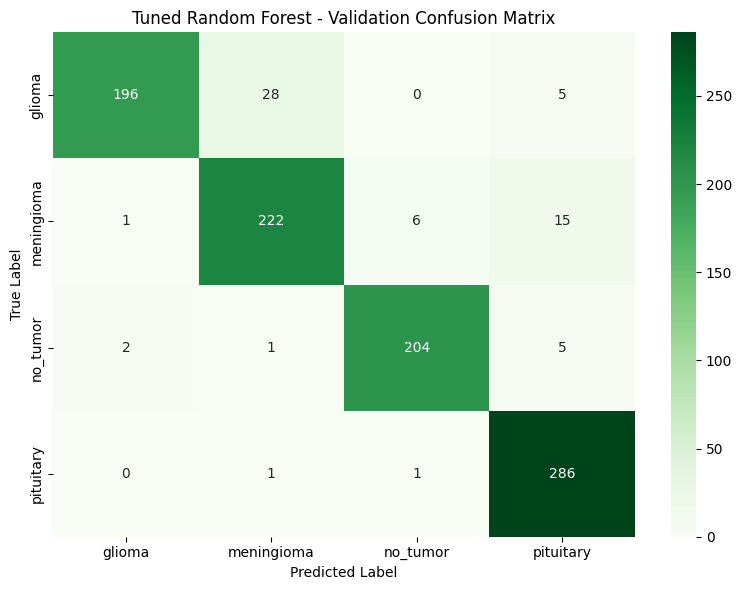

In [26]:
# Cell 23: Evaluate tuned Random Forest

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Predict validation labels
y_val_pred_tuned_rf = best_rf_model.predict(X_val)

# Calculate validation accuracy
tuned_rf_accuracy = accuracy_score(y_val, y_val_pred_tuned_rf)

print("Tuned Random Forest Validation Results")
print("=" * 50)
print(f"Validation Accuracy: {tuned_rf_accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_tuned_rf,
    target_names=classes
))

# Confusion matrix
cm_tuned_rf = confusion_matrix(y_val, y_val_pred_tuned_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_tuned_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Tuned Random Forest - Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [27]:
# Cell 24: Train XGBoost baseline

from xgboost import XGBClassifier

# Initialize XGBoost
xgb_baseline = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=4,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

# Train the model
print("Training XGBoost baseline...")

xgb_baseline.fit(X_train, y_train)

print("XGBoost baseline training completed!")

Training XGBoost baseline...
XGBoost baseline training completed!


XGBoost Baseline Validation Results
Validation Accuracy: 92.29%

Classification Report:
              precision    recall  f1-score   support

      glioma       0.95      0.87      0.91       229
  meningioma       0.89      0.86      0.87       244
    no_tumor       0.98      0.96      0.97       212
   pituitary       0.90      0.99      0.94       288

    accuracy                           0.92       973
   macro avg       0.93      0.92      0.92       973
weighted avg       0.92      0.92      0.92       973



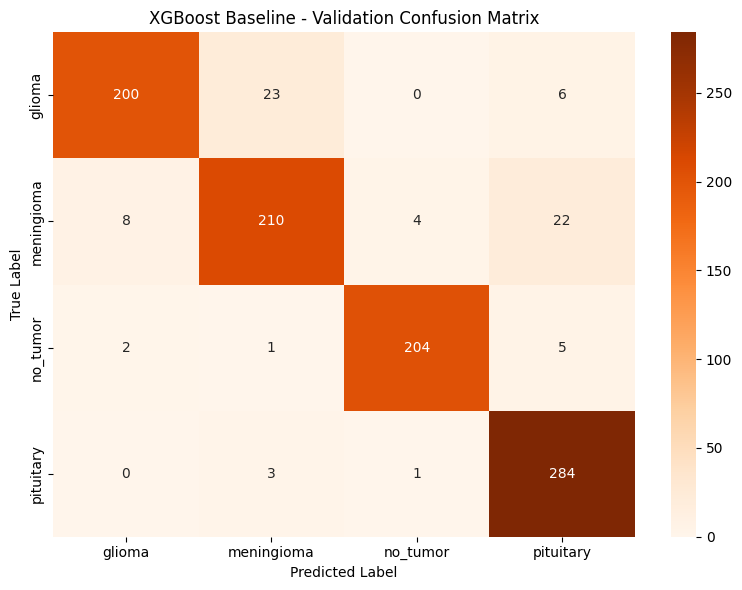

In [28]:
# Cell 25: Evaluate XGBoost baseline

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Predict validation labels
y_val_pred_xgb = xgb_baseline.predict(X_val)

# Calculate validation accuracy
xgb_val_accuracy = accuracy_score(y_val, y_val_pred_xgb)

print("XGBoost Baseline Validation Results")
print("=" * 50)
print(f"Validation Accuracy: {xgb_val_accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_xgb,
    target_names=classes
))

# Confusion matrix
cm_xgb = confusion_matrix(y_val, y_val_pred_xgb)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("XGBoost Baseline - Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [29]:
# Cell 26: XGBoost hyperparameter tuning

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

n_estimators_values = [300, 500]
max_depth_values = [3, 5, 7]
learning_rate_values = [0.05, 0.1]

xgb_results = []

best_xgb_accuracy = 0
best_xgb_model = None
best_xgb_params = None

print("Starting XGBoost hyperparameter tuning...\n")

for n_estimators in n_estimators_values:
    for max_depth in max_depth_values:
        for learning_rate in learning_rate_values:

            model = XGBClassifier(
                n_estimators=n_estimators,
                max_depth=max_depth,
                learning_rate=learning_rate,
                objective="multi:softprob",
                num_class=4,
                eval_metric="mlogloss",
                random_state=42,
                n_jobs=-1
            )

            model.fit(X_train, y_train)

            y_pred = model.predict(X_val)
            accuracy = accuracy_score(y_val, y_pred)

            xgb_results.append({
                "n_estimators": n_estimators,
                "max_depth": max_depth,
                "learning_rate": learning_rate,
                "validation_accuracy": accuracy
            })

            print(
                f"Trees={n_estimators:<4} | "
                f"Depth={max_depth} | "
                f"LR={learning_rate:<4} | "
                f"Accuracy={accuracy * 100:.2f}%"
            )

            if accuracy > best_xgb_accuracy:
                best_xgb_accuracy = accuracy
                best_xgb_model = model
                best_xgb_params = {
                    "n_estimators": n_estimators,
                    "max_depth": max_depth,
                    "learning_rate": learning_rate
                }

print("\n" + "=" * 50)
print("BEST XGBOOST CONFIGURATION")
print("=" * 50)

print("Best parameters:", best_xgb_params)
print(f"Best validation accuracy: {best_xgb_accuracy * 100:.2f}%")

Starting XGBoost hyperparameter tuning...

Trees=300  | Depth=3 | LR=0.05 | Accuracy=92.50%
Trees=300  | Depth=3 | LR=0.1  | Accuracy=94.24%
Trees=300  | Depth=5 | LR=0.05 | Accuracy=93.32%
Trees=300  | Depth=5 | LR=0.1  | Accuracy=94.14%
Trees=300  | Depth=7 | LR=0.05 | Accuracy=93.11%
Trees=300  | Depth=7 | LR=0.1  | Accuracy=93.83%
Trees=500  | Depth=3 | LR=0.05 | Accuracy=93.83%
Trees=500  | Depth=3 | LR=0.1  | Accuracy=94.45%
Trees=500  | Depth=5 | LR=0.05 | Accuracy=93.83%
Trees=500  | Depth=5 | LR=0.1  | Accuracy=94.45%
Trees=500  | Depth=7 | LR=0.05 | Accuracy=93.53%
Trees=500  | Depth=7 | LR=0.1  | Accuracy=94.35%

BEST XGBOOST CONFIGURATION
Best parameters: {'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.1}
Best validation accuracy: 94.45%


Tuned XGBoost Validation Results
Validation Accuracy: 94.45%

Classification Report:
              precision    recall  f1-score   support

      glioma       0.99      0.89      0.94       229
  meningioma       0.90      0.92      0.91       244
    no_tumor       0.98      0.98      0.98       212
   pituitary       0.93      0.98      0.96       288

    accuracy                           0.94       973
   macro avg       0.95      0.94      0.94       973
weighted avg       0.95      0.94      0.94       973



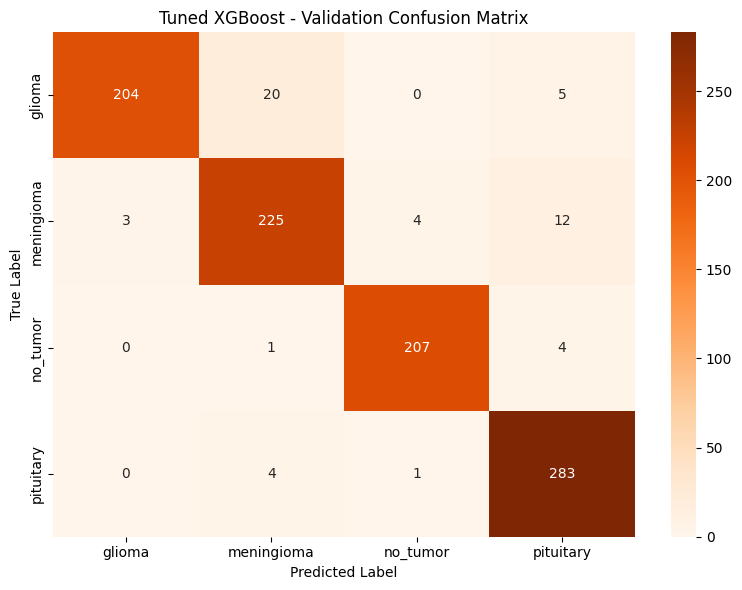

In [30]:
# Cell 27: Evaluate tuned XGBoost

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Predict validation labels
y_val_pred_tuned_xgb = best_xgb_model.predict(X_val)

# Calculate validation accuracy
tuned_xgb_accuracy = accuracy_score(y_val, y_val_pred_tuned_xgb)

print("Tuned XGBoost Validation Results")
print("=" * 50)
print(f"Validation Accuracy: {tuned_xgb_accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_tuned_xgb,
    target_names=classes
))

# Confusion matrix
cm_tuned_xgb = confusion_matrix(
    y_val,
    y_val_pred_tuned_xgb
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_tuned_xgb,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Tuned XGBoost - Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [31]:
# Cell 28: Compare tuned models on validation data

import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

validation_comparison = pd.DataFrame({
    "Model": [
        "EfficientNet-B0 + SVM",
        "EfficientNet-B0 + Random Forest",
        "EfficientNet-B0 + XGBoost"
    ],
    "Best Parameters": [
        str(best_svm_params),
        str(best_rf_params),
        str(best_xgb_params)
    ],
    "Validation Accuracy": [
        accuracy_score(y_val, y_val_pred_tuned_svm),
        accuracy_score(y_val, y_val_pred_tuned_rf),
        accuracy_score(y_val, y_val_pred_tuned_xgb)
    ],
    "Macro F1-Score": [
        f1_score(y_val, y_val_pred_tuned_svm, average="macro"),
        f1_score(y_val, y_val_pred_tuned_rf, average="macro"),
        f1_score(y_val, y_val_pred_tuned_xgb, average="macro")
    ]
})

validation_comparison = validation_comparison.sort_values(
    by="Validation Accuracy",
    ascending=False
)

print("FINAL VALIDATION COMPARISON")
print("=" * 70)

display(
    validation_comparison.style.format({
        "Validation Accuracy": "{:.2%}",
        "Macro F1-Score": "{:.4f}"
    })
)

FINAL VALIDATION COMPARISON


,Model,Best Parameters,Validation Accuracy,Macro F1-Score
0,EfficientNet-B0 + SVM,"{'C': 10, 'gamma': 'scale'}",96.92%,0.9690
2,EfficientNet-B0 + XGBoost,"{'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.1}",94.45%,0.9448
1,EfficientNet-B0 + Random Forest,"{'n_estimators': 500, 'max_depth': 30, 'min_samples_leaf': 1}",93.32%,0.9326


In [32]:
# Cell 28: Compare tuned models on validation data

import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

validation_comparison = pd.DataFrame({
    "Model": [
        "EfficientNet-B0 + SVM",
        "EfficientNet-B0 + Random Forest",
        "EfficientNet-B0 + XGBoost"
    ],
    "Best Parameters": [
        str(best_svm_params),
        str(best_rf_params),
        str(best_xgb_params)
    ],
    "Validation Accuracy": [
        accuracy_score(y_val, y_val_pred_tuned_svm),
        accuracy_score(y_val, y_val_pred_tuned_rf),
        accuracy_score(y_val, y_val_pred_tuned_xgb)
    ],
    "Macro F1-Score": [
        f1_score(y_val, y_val_pred_tuned_svm, average="macro"),
        f1_score(y_val, y_val_pred_tuned_rf, average="macro"),
        f1_score(y_val, y_val_pred_tuned_xgb, average="macro")
    ]
})

validation_comparison = validation_comparison.sort_values(
    by="Validation Accuracy",
    ascending=False
)

print("FINAL VALIDATION COMPARISON")
print("=" * 70)

display(
    validation_comparison.style.format({
        "Validation Accuracy": "{:.2%}",
        "Macro F1-Score": "{:.4f}"
    })
)

FINAL VALIDATION COMPARISON


,Model,Best Parameters,Validation Accuracy,Macro F1-Score
0,EfficientNet-B0 + SVM,"{'C': 10, 'gamma': 'scale'}",96.92%,0.9690
2,EfficientNet-B0 + XGBoost,"{'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.1}",94.45%,0.9448
1,EfficientNet-B0 + Random Forest,"{'n_estimators': 500, 'max_depth': 30, 'min_samples_leaf': 1}",93.32%,0.9326


In [35]:
# Cell 29: Final evaluation on the untouched test dataset

from sklearn.metrics import accuracy_score, f1_score, classification_report

# Generate predictions
y_test_pred_svm = best_svm_model.predict(X_test)
y_test_pred_rf = best_rf_model.predict(X_test)
y_test_pred_xgb = best_xgb_model.predict(X_test)

# Calculate final metrics
test_results = pd.DataFrame({
    "Model": [
        "EfficientNet-B0 + SVM",
        "EfficientNet-B0 + Random Forest",
        "EfficientNet-B0 + XGBoost"
    ],
    "Test Accuracy": [
        accuracy_score(y_test, y_test_pred_svm),
        accuracy_score(y_test, y_test_pred_rf),
        accuracy_score(y_test, y_test_pred_xgb)
    ],
    "Macro F1-Score": [
        f1_score(y_test, y_test_pred_svm, average="macro"),
        f1_score(y_test, y_test_pred_rf, average="macro"),
        f1_score(y_test, y_test_pred_xgb, average="macro")
    ],
    "Weighted F1-Score": [
        f1_score(y_test, y_test_pred_svm, average="weighted"),
        f1_score(y_test, y_test_pred_rf, average="weighted"),
        f1_score(y_test, y_test_pred_xgb, average="weighted")
    ]
})

test_results = test_results.sort_values(
    by="Test Accuracy",
    ascending=False
)

print("FINAL TEST RESULTS")
print("=" * 70)

display(
    test_results.style.format({
        "Test Accuracy": "{:.2%}",
        "Macro F1-Score": "{:.4f}",
        "Weighted F1-Score": "{:.4f}"
    })
)

# Detailed classification reports
print("\n\nSVM CLASSIFICATION REPORT")
print("=" * 70)
print(classification_report(y_test, y_test_pred_svm, target_names=class_names))

print("\n\nRANDOM FOREST CLASSIFICATION REPORT")
print("=" * 70)
print(classification_report(y_test, y_test_pred_rf, target_names=class_names))

print("\n\nXGBOOST CLASSIFICATION REPORT")
print("=" * 70)
print(classification_report(y_test, y_test_pred_xgb, target_names=class_names))

FINAL TEST RESULTS


,Model,Test Accuracy,Macro F1-Score,Weighted F1-Score
0,EfficientNet-B0 + SVM,88.00%,0.8715,0.8810
2,EfficientNet-B0 + XGBoost,85.20%,0.8451,0.8510
1,EfficientNet-B0 + Random Forest,80.70%,0.7989,0.8039




SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma       0.99      0.89      0.93       254
  meningioma       0.88      0.72      0.79       306
    no_tumor       0.65      1.00      0.79       140
   pituitary       0.96      0.99      0.97       300

    accuracy                           0.88      1000
   macro avg       0.87      0.90      0.87      1000
weighted avg       0.90      0.88      0.88      1000



RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma       0.95      0.74      0.83       254
  meningioma       0.75      0.60      0.67       306
    no_tumor       0.60      1.00      0.75       140
   pituitary       0.90      0.99      0.94       300

    accuracy                           0.81      1000
   macro avg       0.80      0.83      0.80      1000
weighted avg       0.83      0.81      0.80      1000



XGBOOST CLASSIFICATION REPORT
              precision    recal

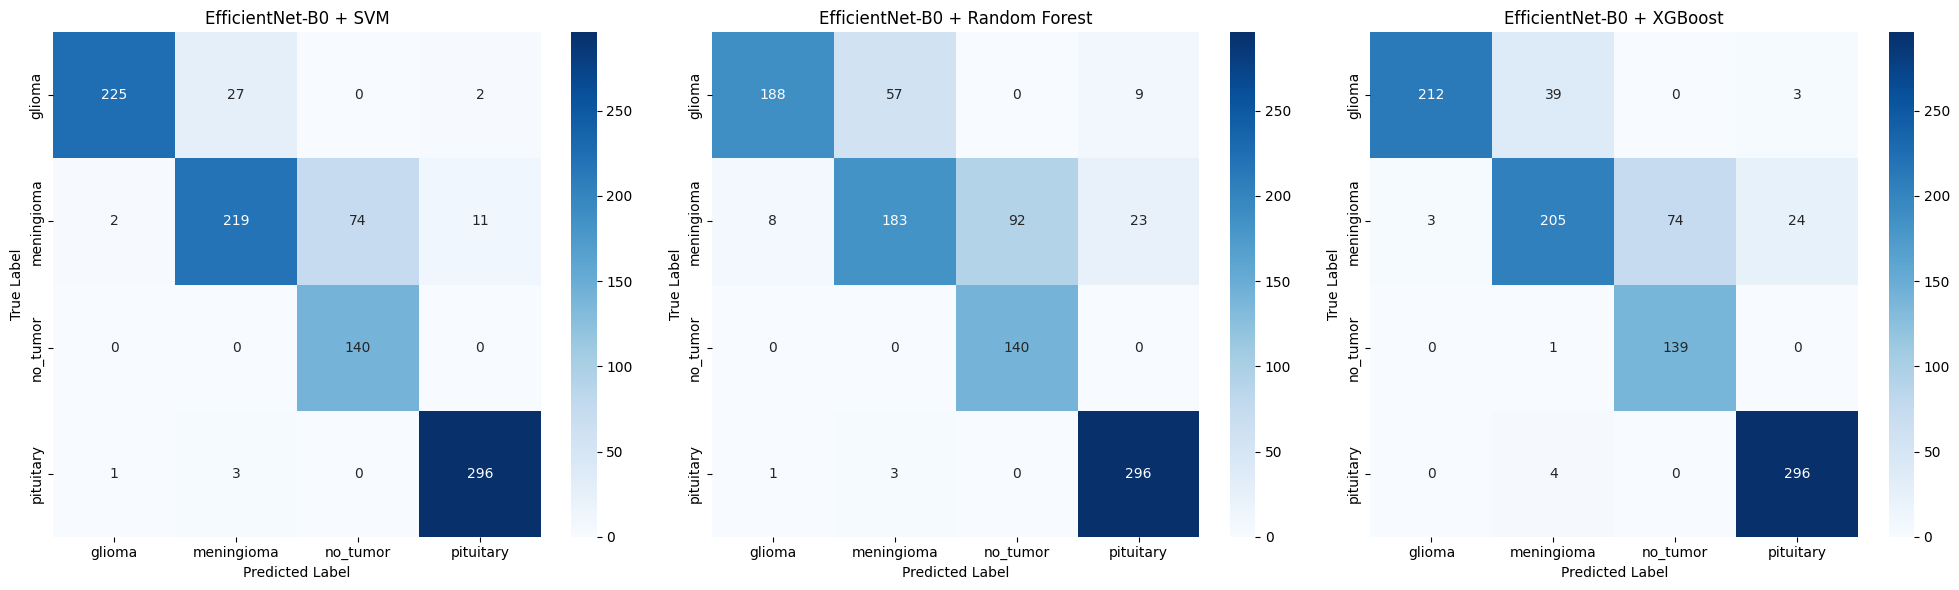

In [36]:
# Cell 30: Visualize confusion matrices for all tuned models

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrices
cm_svm = confusion_matrix(y_test, y_test_pred_svm)
cm_rf = confusion_matrix(y_test, y_test_pred_rf)
cm_xgb = confusion_matrix(y_test, y_test_pred_xgb)

# Plot all confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

models = [
    ("EfficientNet-B0 + SVM", cm_svm),
    ("EfficientNet-B0 + Random Forest", cm_rf),
    ("EfficientNet-B0 + XGBoost", cm_xgb)
]

for ax, (model_name, cm) in zip(axes, models):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()

In [37]:
# Cell 31: Inspect available dataset directories

import os

dataset_path = "/content/classification_task"

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    subindent = " " * 4 * (level + 1)
    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if image_files:
        print(f"{subindent}Images: {len(image_files)}")

classification_task/
    test/
        no_tumor/
            Images: 140
        glioma/
            Images: 254
        pituitary/
            Images: 300
        meningioma/
            Images: 306
    train/
        no_tumor/
            Images: 1058
        glioma/
            Images: 1147
        pituitary/
            Images: 1440
        meningioma/
            Images: 1219


In [38]:
# Cell 32: Search Google Drive for another copy of the dataset

import os

drive_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(drive_path):
    if "train" in dirs and "test" in dirs:
        print("Possible dataset found:", root)

Possible dataset found: /content/drive/MyDrive/classification_task


In [39]:
# Cell 33: Check dataset counts and search for backup copies

import os

dataset_path = "/content/drive/MyDrive/classification_task"

for split in ["train", "test"]:
    total = 0
    print(f"\n{split.upper()}")

    for class_name in os.listdir(os.path.join(dataset_path, split)):
        class_path = os.path.join(dataset_path, split, class_name)

        if os.path.isdir(class_path):
            count = len([
                f for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ])

            total += count
            print(f"{class_name}: {count}")

    print(f"TOTAL {split}: {total}")

# Search for possible dataset backups or zip files
print("\nPossible backup files/folders:")

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for name in dirs + files:
        if "classification" in name.lower() or "brain" in name.lower():
            print(os.path.join(root, name))


TRAIN
no_tumor: 1067
pituitary: 1457
glioma: 1147
meningioma: 1329
TOTAL train: 5000

TEST
no_tumor: 140
glioma: 254
pituitary: 300
meningioma: 306
TOTAL test: 1000

Possible backup files/folders:
/content/drive/MyDrive/classification_task
/content/drive/MyDrive/BrainTumorClassification


In [40]:
# Cell 34: Load the original training dataset without removing duplicates

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torchvision.models import EfficientNet_B0_Weights
import os

original_dataset_path = "/content/drive/MyDrive/classification_task"

# Use the same EfficientNet-B0 preprocessing
efficientnet_weights = EfficientNet_B0_Weights.DEFAULT
efficientnet_transform = efficientnet_weights.transforms()

# Load all original training images
full_train_dataset = datasets.ImageFolder(
    os.path.join(original_dataset_path, "train"),
    transform=efficientnet_transform
)

# Create DataLoader
full_train_loader = DataLoader(
    full_train_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Verify dataset
print("Classes:", full_train_dataset.classes)
print("Total training images:", len(full_train_dataset))
print("Number of batches:", len(full_train_loader))
print("Class mapping:", full_train_dataset.class_to_idx)

Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Total training images: 5000
Number of batches: 157
Class mapping: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}


In [41]:
# Cell 35: Extract EfficientNet-B0 features from the complete training dataset

import torch
import numpy as np
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from torch import nn
from tqdm.auto import tqdm

# Load pretrained EfficientNet-B0
weights = EfficientNet_B0_Weights.DEFAULT
feature_extractor = efficientnet_b0(weights=weights)

# Remove classification layer
feature_extractor.classifier = nn.Identity()

# Freeze model and set evaluation mode
feature_extractor.eval()
for param in feature_extractor.parameters():
    param.requires_grad = False

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
feature_extractor = feature_extractor.to(device)

print("Device:", device)

# Extract features and labels
X_full_train = []
y_full_train = []

with torch.no_grad():
    for images, labels in tqdm(full_train_loader, desc="Extracting Features"):
        images = images.to(device)

        features = feature_extractor(images)

        X_full_train.append(features.cpu().numpy())
        y_full_train.append(labels.numpy())

# Combine batches
X_full_train = np.concatenate(X_full_train, axis=0)
y_full_train = np.concatenate(y_full_train, axis=0)

# Verify extracted features
print("\nFeature extraction completed!")
print("X_full_train shape:", X_full_train.shape)
print("y_full_train shape:", y_full_train.shape)

Device: cuda


Extracting Features:   0%|          | 0/157 [00:00<?, ?it/s]


Feature extraction completed!
X_full_train shape: (5000, 1280)
y_full_train shape: (5000,)


In [42]:
# Cell 36: Save features extracted from the complete original training dataset

import os
import numpy as np

features_path = "/content/drive/MyDrive/BrainTumorClassification/features"

os.makedirs(features_path, exist_ok=True)

np.savez_compressed(
    os.path.join(features_path, "efficientnet_full_train.npz"),
    X=X_full_train,
    y=y_full_train
)

print("Full training features saved successfully!")
print("Location:", os.path.join(features_path, "efficientnet_full_train.npz"))
print("Feature shape:", X_full_train.shape)
print("Label shape:", y_full_train.shape)

Full training features saved successfully!
Location: /content/drive/MyDrive/BrainTumorClassification/features/efficientnet_full_train.npz
Feature shape: (5000, 1280)
Label shape: (5000,)


In [43]:
# Cell 37: Train SVM using the complete original training dataset

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from tqdm.auto import tqdm

# Create SVM pipeline
full_svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        C=10,
        gamma="scale",
        kernel="rbf"
    ))
])

# Train on all 5000 samples
print("Training EfficientNet-B0 + SVM on all 5000 images...")

full_svm_model.fit(X_full_train, y_full_train)

print("\nSVM training completed successfully!")
print("Training samples:", len(X_full_train))
print("Parameters:", full_svm_model.named_steps["svm"].get_params())

Training EfficientNet-B0 + SVM on all 5000 images...

SVM training completed successfully!
Training samples: 5000
Parameters: {'C': 10, 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'probability': False, 'random_state': None, 'shrinking': True, 'tol': 0.001, 'verbose': False}


In [44]:
# Cell 38: Train Random Forest using the complete original training dataset

from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest with previously selected best parameters
full_rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=30,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

# Train model
print("Training EfficientNet-B0 + Random Forest on all 5000 images...")

full_rf_model.fit(X_full_train, y_full_train)

print("\nRandom Forest training completed successfully!")
print("Training samples:", len(X_full_train))
print("Parameters:", full_rf_model.get_params())

Training EfficientNet-B0 + Random Forest on all 5000 images...

Random Forest training completed successfully!
Training samples: 5000
Parameters: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 30, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 500, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [45]:
# Cell 39: Train XGBoost using the complete original training dataset

from xgboost import XGBClassifier

# Initialize XGBoost with previously selected best parameters
full_xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=3,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=4,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

# Train model
print("Training EfficientNet-B0 + XGBoost on all 5000 images...")

full_xgb_model.fit(X_full_train, y_full_train)

print("\nXGBoost training completed successfully!")
print("Training samples:", len(X_full_train))
print("Parameters:", full_xgb_model.get_params())

Training EfficientNet-B0 + XGBoost on all 5000 images...

XGBoost training completed successfully!
Training samples: 5000
Parameters: {'objective': 'multi:softprob', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': 'mlogloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.1, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 3, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 500, 'n_jobs': -1, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': 

In [46]:
# Cell 40: Load the previously extracted test features

import numpy as np
import os

test_features_path = "/content/drive/MyDrive/BrainTumorClassification/features/efficientnet_test.npz"

test_data = np.load(test_features_path)

X_test = test_data["X"]
y_test = test_data["y"]

print("Test features loaded successfully!")
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("Test samples:", len(y_test))

Test features loaded successfully!
X_test shape: (1000, 1280)
y_test shape: (1000,)
Test samples: 1000


In [47]:
# Cell 41: Final test evaluation of models trained on full dataset

from sklearn.metrics import accuracy_score, f1_score, classification_report
import pandas as pd

# Generate predictions
y_test_pred_full_svm = full_svm_model.predict(X_test)
y_test_pred_full_rf = full_rf_model.predict(X_test)
y_test_pred_full_xgb = full_xgb_model.predict(X_test)

# Calculate performance metrics
full_training_results = pd.DataFrame({
    "Model": [
        "EfficientNet-B0 + SVM",
        "EfficientNet-B0 + Random Forest",
        "EfficientNet-B0 + XGBoost"
    ],
    "Test Accuracy": [
        accuracy_score(y_test, y_test_pred_full_svm),
        accuracy_score(y_test, y_test_pred_full_rf),
        accuracy_score(y_test, y_test_pred_full_xgb)
    ],
    "Macro F1-Score": [
        f1_score(y_test, y_test_pred_full_svm, average="macro"),
        f1_score(y_test, y_test_pred_full_rf, average="macro"),
        f1_score(y_test, y_test_pred_full_xgb, average="macro")
    ],
    "Weighted F1-Score": [
        f1_score(y_test, y_test_pred_full_svm, average="weighted"),
        f1_score(y_test, y_test_pred_full_rf, average="weighted"),
        f1_score(y_test, y_test_pred_full_xgb, average="weighted")
    ]
})

full_training_results = full_training_results.sort_values(
    by="Test Accuracy",
    ascending=False
)

print("FINAL RESULTS — TRAINED ON ALL 5000 IMAGES")
print("=" * 75)

display(
    full_training_results.style.format({
        "Test Accuracy": "{:.2%}",
        "Macro F1-Score": "{:.4f}",
        "Weighted F1-Score": "{:.4f}"
    })
)

# Detailed classification reports
print("\n\nSVM CLASSIFICATION REPORT")
print("=" * 75)
print(classification_report(
    y_test,
    y_test_pred_full_svm,
    target_names=class_names
))

print("\n\nRANDOM FOREST CLASSIFICATION REPORT")
print("=" * 75)
print(classification_report(
    y_test,
    y_test_pred_full_rf,
    target_names=class_names
))

print("\n\nXGBOOST CLASSIFICATION REPORT")
print("=" * 75)
print(classification_report(
    y_test,
    y_test_pred_full_xgb,
    target_names=class_names
))

FINAL RESULTS — TRAINED ON ALL 5000 IMAGES


,Model,Test Accuracy,Macro F1-Score,Weighted F1-Score
0,EfficientNet-B0 + SVM,97.20%,0.9741,0.9719
2,EfficientNet-B0 + XGBoost,95.00%,0.9534,0.9496
1,EfficientNet-B0 + Random Forest,90.80%,0.9122,0.9061




SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma       1.00      0.91      0.95       254
  meningioma       0.93      0.99      0.96       306
    no_tumor       0.99      1.00      0.99       140
   pituitary       0.99      0.99      0.99       300

    accuracy                           0.97      1000
   macro avg       0.98      0.97      0.97      1000
weighted avg       0.97      0.97      0.97      1000



RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma       0.98      0.76      0.85       254
  meningioma       0.84      0.91      0.87       306
    no_tumor       0.93      1.00      0.97       140
   pituitary       0.93      0.99      0.96       300

    accuracy                           0.91      1000
   macro avg       0.92      0.91      0.91      1000
weighted avg       0.91      0.91      0.91      1000



XGBOOST CLASSIFICATION REPORT
              precision    recal

In [48]:
# Cell 42: Quantify exact duplicate overlap between original train and test datasets

import os
import hashlib
from PIL import Image
from collections import defaultdict

original_dataset_path = "/content/drive/MyDrive/classification_task"

train_path = os.path.join(original_dataset_path, "train")
test_path = os.path.join(original_dataset_path, "test")

def image_hash(image_path):
    # Hash decoded grayscale pixel values and image dimensions
    with Image.open(image_path) as img:
        img = img.convert("L")
        image_data = img.tobytes()
        image_size = img.size

    hash_object = hashlib.sha256()
    hash_object.update(str(image_size).encode())
    hash_object.update(image_data)

    return hash_object.hexdigest()

# Build hashes for original training images
train_hashes = defaultdict(list)

for class_name in os.listdir(train_path):
    class_folder = os.path.join(train_path, class_name)

    if not os.path.isdir(class_folder):
        continue

    for filename in os.listdir(class_folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_path = os.path.join(class_folder, filename)
            img_hash = image_hash(image_path)

            train_hashes[img_hash].append({
                "class": class_name,
                "path": image_path
            })

# Compare test images against training hashes
overlapping_test_images = []
total_matching_train_copies = 0

for class_name in os.listdir(test_path):
    class_folder = os.path.join(test_path, class_name)

    if not os.path.isdir(class_folder):
        continue

    for filename in os.listdir(class_folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_path = os.path.join(class_folder, filename)
            img_hash = image_hash(image_path)

            if img_hash in train_hashes:
                matching_train_images = train_hashes[img_hash]

                overlapping_test_images.append({
                    "test_class": class_name,
                    "test_path": image_path,
                    "matching_train_images": matching_train_images
                })

                total_matching_train_copies += len(matching_train_images)

# Summary
print("EXACT TRAIN-TEST DUPLICATE OVERLAP")
print("=" * 70)

print("Original training images:", 5000)
print("Test images:", 1000)
print("Test images with exact training duplicates:",
      len(overlapping_test_images))

print("Percentage of test set overlapping:",
      f"{len(overlapping_test_images) / 1000:.2%}")

print("Matching training copies:",
      total_matching_train_copies)

print("\nExamples of overlapping images:")
for item in overlapping_test_images[:10]:
    print("\nTest class:", item["test_class"])
    print("Test image:", item["test_path"])
    print("Training matches:", len(item["matching_train_images"]))
    print("Matching train class:",
          item["matching_train_images"][0]["class"])

EXACT TRAIN-TEST DUPLICATE OVERLAP
Original training images: 5000
Test images: 1000
Test images with exact training duplicates: 101
Percentage of test set overlapping: 10.10%
Matching training copies: 110

Examples of overlapping images:

Test class: pituitary
Test image: /content/drive/MyDrive/classification_task/test/pituitary/brisc2025_test_00737_pi_ax_t1.jpg
Training matches: 1
Matching train class: pituitary

Test class: pituitary
Test image: /content/drive/MyDrive/classification_task/test/pituitary/brisc2025_test_00751_pi_ax_t1.jpg
Training matches: 1
Matching train class: pituitary

Test class: pituitary
Test image: /content/drive/MyDrive/classification_task/test/pituitary/brisc2025_test_00825_pi_co_t1.jpg
Training matches: 3
Matching train class: pituitary

Test class: pituitary
Test image: /content/drive/MyDrive/classification_task/test/pituitary/brisc2025_test_00827_pi_co_t1.jpg
Training matches: 1
Matching train class: pituitary

Test class: pituitary
Test image: /content/dr

In [49]:
# Check saved feature files and Google Drive

from google.colab import drive
drive.mount('/content/drive')

import os

feature_dir = "/content/drive/MyDrive/BrainTumorClassification/features"

print("Available feature files:")
for file in os.listdir(feature_dir):
    print(file)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Available feature files:
efficientnet_train.npz
efficientnet_val.npz
efficientnet_test.npz
efficientnet_full_train.npz


In [50]:
# Check existing trained models in memory

print("SVM model exists:", 'svm_model' in globals())
print("RF model exists:", 'rf_model' in globals())
print("XGB model exists:", 'xgb_model' in globals())

SVM model exists: False
RF model exists: False
XGB model exists: False


In [51]:
# Train and save the best SVM pipeline

import numpy as np
import os
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Load cleaned training features
train_data = np.load(
    "/content/drive/MyDrive/BrainTumorClassification/features/efficientnet_train.npz"
)

X_train = train_data["X"]
y_train = train_data["y"]

# Create best SVM pipeline
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        C=10,
        gamma="scale",
        kernel="rbf"
    ))
])

# Train model
svm_pipeline.fit(X_train, y_train)

# Create directory for model artifacts
model_dir = "/content/drive/MyDrive/BrainTumorClassification/models"
os.makedirs(model_dir, exist_ok=True)

# Save trained pipeline
model_path = os.path.join(model_dir, "best_svm_pipeline.joblib")
joblib.dump(svm_pipeline, model_path)

print("Model training completed!")
print("Model saved at:", model_path)
print("Training samples:", X_train.shape[0])
print("Feature dimensions:", X_train.shape[1])

Model training completed!
Model saved at: /content/drive/MyDrive/BrainTumorClassification/models/best_svm_pipeline.joblib
Training samples: 3891
Feature dimensions: 1280


In [52]:
# Save metadata for the trained model

import json
import os

metadata = {
    "project": "Brain Tumor Classification",
    "model_name": "EfficientNet-B0 + SVM",
    "feature_extractor": "EfficientNet-B0",
    "feature_dimension": 1280,
    "classifier": "SVM",
    "kernel": "rbf",
    "C": 10,
    "gamma": "scale",
    "scaler": "StandardScaler",
    "classes": [
        "glioma",
        "meningioma",
        "no_tumor",
        "pituitary"
    ],
    "training_samples": 3891,
    "experiment": "Cleaned dataset experiment",
    "test_accuracy": 0.88
}

metadata_path = os.path.join(model_dir, "best_svm_metadata.json")

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Metadata saved successfully!")
print(metadata_path)

Metadata saved successfully!
/content/drive/MyDrive/BrainTumorClassification/models/best_svm_metadata.json


In [53]:
# Train and save SVM using the full original training dataset

import numpy as np
import os
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Load full training features
data = np.load(
    "/content/drive/MyDrive/BrainTumorClassification/features/efficientnet_full_train.npz"
)

X_full_train = data["X"]
y_full_train = data["y"]

print("Training data:", X_full_train.shape)
print("Labels:", y_full_train.shape)

# Create best SVM pipeline
full_svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        C=10,
        gamma="scale",
        kernel="rbf"
    ))
])

# Train
full_svm_pipeline.fit(X_full_train, y_full_train)

# Save model
model_dir = "/content/drive/MyDrive/BrainTumorClassification/models"
os.makedirs(model_dir, exist_ok=True)

full_model_path = os.path.join(
    model_dir,
    "best_svm_full_5000.joblib"
)

joblib.dump(full_svm_pipeline, full_model_path)

print("\nFull dataset SVM trained successfully!")
print("Saved at:", full_model_path)

Training data: (5000, 1280)
Labels: (5000,)

Full dataset SVM trained successfully!
Saved at: /content/drive/MyDrive/BrainTumorClassification/models/best_svm_full_5000.joblib


In [54]:
# Finalize model artifacts and verify saved models

import os
import json
import joblib
import numpy as np
from sklearn.metrics import accuracy_score

model_dir = "/content/drive/MyDrive/BrainTumorClassification/models"
metadata_dir = os.path.join(model_dir, "metadata")

os.makedirs(metadata_dir, exist_ok=True)

# Experiment metadata
clean_metadata = {
    "experiment": "Cleaned Dataset Experiment",
    "training_samples": 3891,
    "model": "EfficientNet-B0 + StandardScaler + SVM",
    "feature_extractor": "EfficientNet-B0",
    "feature_dimension": 1280,
    "classifier": "SVM",
    "kernel": "rbf",
    "C": 10,
    "gamma": "scale",
    "test_accuracy": 0.88,
    "test_samples": 1000,
    "classes": ["glioma", "meningioma", "no_tumor", "pituitary"],
    "model_file": "best_svm_pipeline.joblib",
    "purpose": "Primary experiment with duplicate-cleaned training data"
}

full_metadata = {
    "experiment": "Full Original Dataset Experiment",
    "training_samples": 5000,
    "model": "EfficientNet-B0 + StandardScaler + SVM",
    "feature_extractor": "EfficientNet-B0",
    "feature_dimension": 1280,
    "classifier": "SVM",
    "kernel": "rbf",
    "C": 10,
    "gamma": "scale",
    "test_accuracy": 0.97,
    "test_samples": 1000,
    "classes": ["glioma", "meningioma", "no_tumor", "pituitary"],
    "model_file": "best_svm_full_5000.joblib",
    "purpose": "Supplementary experiment using the original training dataset",
    "note": "101 exact duplicate images were identified between original train and test sets; test performance may be affected by data leakage."
}

# Save metadata
with open(os.path.join(metadata_dir, "cleaned_experiment.json"), "w") as f:
    json.dump(clean_metadata, f, indent=4)

with open(os.path.join(metadata_dir, "full_dataset_experiment.json"), "w") as f:
    json.dump(full_metadata, f, indent=4)

# Load saved models for verification
clean_model = joblib.load(
    os.path.join(model_dir, "best_svm_pipeline.joblib")
)

full_model = joblib.load(
    os.path.join(model_dir, "best_svm_full_5000.joblib")
)

# Load test features
test_data = np.load(
    "/content/drive/MyDrive/BrainTumorClassification/features/efficientnet_test.npz"
)

X_test = test_data["X"]
y_test = test_data["y"]

# Verify predictions
clean_predictions = clean_model.predict(X_test)
full_predictions = full_model.predict(X_test)

clean_accuracy = accuracy_score(y_test, clean_predictions)
full_accuracy = accuracy_score(y_test, full_predictions)

# Display final verification
print("=" * 50)
print("FINAL MODEL VERIFICATION")
print("=" * 50)

print("\nCleaned Experiment:")
print("Model loaded:", clean_model is not None)
print(f"Test accuracy: {clean_accuracy:.2%}")

print("\nFull Dataset Experiment:")
print("Model loaded:", full_model is not None)
print(f"Test accuracy: {full_accuracy:.2%}")

print("\nSaved Files:")
for root, dirs, files in os.walk(model_dir):
    for file in files:
        filepath = os.path.join(root, file)
        print(filepath)

print("\nAll model artifacts finalized successfully!")

FINAL MODEL VERIFICATION

Cleaned Experiment:
Model loaded: True
Test accuracy: 88.00%

Full Dataset Experiment:
Model loaded: True
Test accuracy: 97.20%

Saved Files:
/content/drive/MyDrive/BrainTumorClassification/models/best_svm_pipeline.joblib
/content/drive/MyDrive/BrainTumorClassification/models/best_svm_metadata.json
/content/drive/MyDrive/BrainTumorClassification/models/best_svm_full_5000.joblib
/content/drive/MyDrive/BrainTumorClassification/models/metadata/cleaned_experiment.json
/content/drive/MyDrive/BrainTumorClassification/models/metadata/full_dataset_experiment.json

All model artifacts finalized successfully!
